# Time-lapse data tour

A first look at the video dataset behind the division model (Gomez et al. 2022, 704 embryos filmed every
~15 minutes for up to 6 days, each frame labelled with its development stage by an embryologist). The
questions here shaped the pipeline: what a video looks like, when divisions happen, what is messy about the
timestamps, how unbalanced the stages are, and why every split is by patient.

Needs the prepared data: `python scripts/timelapse/prepare_data.py`.

In [1]:
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from embryoscan import paths
from embryoscan.common import figures
from embryoscan.common.figures import plt
from embryoscan.timelapse.labels import PHASE_NAMES, P, onsets

%matplotlib inline

frames = pd.read_csv(paths.TIMELAPSE_TABLE)
split = pd.read_csv(paths.SPLIT_TIMELAPSE)
images = np.load(paths.TIMELAPSE_FRAMES, mmap_mode="r")  # 160 x 160 crops around the embryo, one per frame
print(f"{frames.video.nunique()} videos, {len(frames):,} frames, {frames.patient.nunique()} patients")
frames.head()

704 videos, 310,894 frames, 542 patients


,row,video,frame,hours,phase,patient,missing,crop_x,crop_y
0,0,AA83-7,1,1.4,-1,AA83,False,165,133
1,1,AA83-7,2,1.6,-1,AA83,False,165,133
2,2,AA83-7,3,1.9,-1,AA83,False,165,133
3,3,AA83-7,4,2.1,-1,AA83,False,165,133
4,4,AA83-7,5,2.4,0,AA83,False,165,133


## One embryo, five days

Frames a little after each stage begins, from a training video with typical timing (first division and
blastocyst close to the dataset's medians) whose 3-cell and 4-cell stages are an hour or more apart.

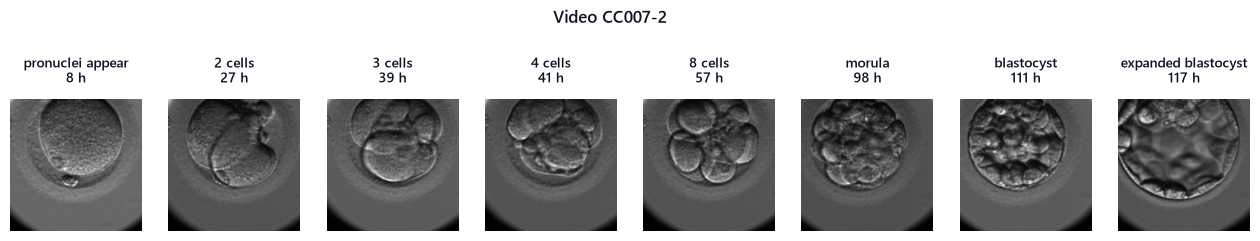

In [2]:
onset_table = pd.DataFrame(
    [{"video": v, **onsets(g.phase.to_numpy(), g.hours.to_numpy())} for v, g in frames.groupby("video")]
).set_index("video")
train = onset_table.loc[split[split.split == "train"].video]
candidates = train[train.tEB.notna() & (train.t4 - train.t3 >= 1)]
distance = (candidates.t2 - onset_table.t2.median()).abs() + (candidates.tB - onset_table.tB.median()).abs()
video = distance.idxmin()
g = frames[(frames.video == video) & ~frames.missing]

show = ["tPNa", "t2", "t3", "t4", "t8", "tM", "tB", "tEB"]
fig, axes = plt.subplots(1, len(show), figsize=(16, 2.8))
for ax, phase in zip(axes, show, strict=True):
    frame = g[g.phase >= P[phase]].iloc[2]
    ax.imshow(images[frame.row], cmap="gray")
    ax.set_title(f"{PHASE_NAMES[P[phase]]}\n{frame.hours:.0f} h", fontsize=10, loc="center")
    ax.axis("off")
fig.suptitle(f"Video {video}", fontweight="semibold", y=1.05)
plt.show()

## When divisions happen

The hour each stage was first reached, across all videos. Early divisions are tightly clustered; later
stages spread out by a day or more, which is where embryos start to differ.

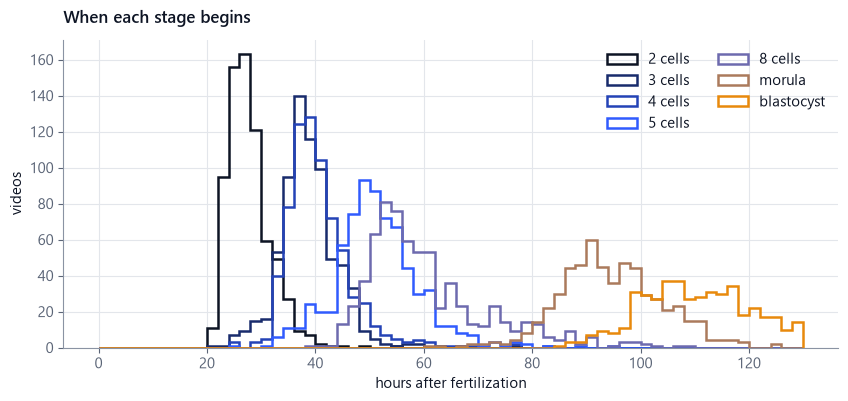

,t2,t3,t4,t5,t8,tB
count,704.0,704.0,704.0,702.0,679.0,474.0
mean,27.8,38.6,40.5,51.2,60.5,111.1
std,4.4,5.4,6.0,8.0,11.4,10.7
min,20.4,20.4,25.0,25.0,39.0,85.3
25%,25.0,35.4,36.7,46.7,52.7,103.2
50%,27.0,38.2,39.4,50.7,57.5,110.2
75%,29.5,41.6,42.8,55.4,65.1,118.2
max,76.5,76.5,82.5,95.2,109.0,138.3


In [3]:
stages = ["t2", "t3", "t4", "t5", "t8", "tM", "tB"]
ramp = LinearSegmentedColormap.from_list("stages", [figures.INK, figures.COBALT, figures.AMBER])
fig, ax = plt.subplots(figsize=(10, 4))
for phase, color in zip(stages, ramp(np.linspace(0, 1, len(stages))), strict=True):
    ax.hist(
        onset_table[phase].dropna(),
        bins=65,
        range=(0, 130),
        histtype="step",
        lw=1.8,
        color=color,
        label=PHASE_NAMES[P[phase]],
    )
ax.set_xlabel("hours after fertilization")
ax.set_ylabel("videos")
ax.set_title("When each stage begins")
ax.legend(ncol=2)
plt.show()
onset_table[["t2", "t3", "t4", "t5", "t8", "tB"]].describe().round(1)

## Messy timestamps

Frame times are rounded to 0.1 h, so neighbouring frames sometimes share one (which breaks tools that expect
strictly increasing times, such as MATLAB's `islocalmax` with sample points). Some timestamp files list a
frame 0 that has no image, and a few JPEGs in the archive are truncated.

In [4]:
step = frames.groupby("video").hours.diff().dropna()
print("most common frame intervals (h):", step.round(2).value_counts().head(4).to_dict())
print(f"repeated timestamps: {(step == 0).sum():,}; backwards steps: {(step < 0).sum()}")
print(f"frame 0 listed without an image: {(frames.frame == 0).sum()} videos")
print(f"frames missing or unreadable: {frames.missing.sum()} of {len(frames):,}")

most common frame intervals (h): {0.3: 149574, 0.2: 144492, 0.4: 13528, 0.0: 1300}
repeated timestamps: 1,300; backwards steps: 0
frame 0 listed without an image: 84 videos
frames missing or unreadable: 4514 of 310,894


## Unbalanced stages

Some stages last half a day (2 cells), others can be over within a frame or two (3 cells when the second
division is in sync). The stage model is trained with class weights so short stages still count, and the
never-go-backwards decoding lets it skip a stage it never saw.

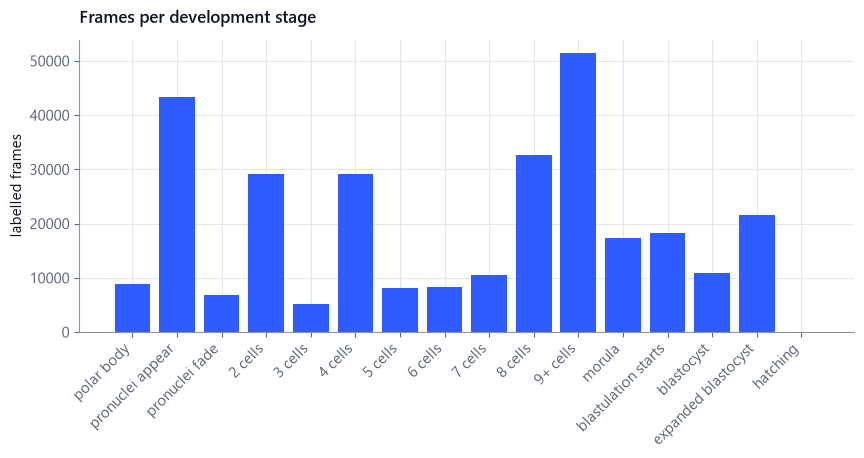

In [5]:
counts = frames[frames.phase >= 0].phase.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar([PHASE_NAMES[i] for i in counts.index], counts.to_numpy(), color=figures.COBALT)
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
ax.set_ylabel("labelled frames")
ax.set_title("Frames per development stage")
plt.show()

## Why splits are by patient

Many embryos have siblings in the dataset (up to 10 from one patient), and siblings share genetics, culture
conditions and imaging. If siblings landed on both sides of a split, the test score would partly measure how
well the model recognises a patient. Every patient's videos therefore go to exactly one of train, val or test.

In [6]:
per_patient = frames.groupby("patient").video.nunique()
video_patient = frames.drop_duplicates("video").set_index("video").patient
with_sibling = video_patient.map(per_patient).ge(2).mean()
print(
    f"{per_patient.size} patients, up to {per_patient.max()} videos each; {with_sibling:.0%} of videos have a sibling"
)
assert (split.groupby("patient").split.nunique() == 1).all(), "a patient appears in two splits"
split.groupby("split").agg(videos=("video", "count"), patients=("patient", "nunique"))

542 patients, up to 10 videos each; 38% of videos have a sibling


,videos,patients
split,,
test,141,108
train,490,380
val,73,54
